# Mystery Curve

In [1]:
import numpy as np
import warnings
warnings.filterwarnings("ignore")
import lightkurve as lk
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import astropy.io
import pandas as pd
import os
import astropy

In [2]:
os.getcwd()

'C:\\Users\\Liam Randell\\psi\\repo\\psi-planet-disintegration\\mystery_curve'

In [3]:
myst_data = pd.read_csv("mystery_transit.csv")

In [4]:
myst_data

,BKJD,SAP_FLUX,FLUX_ERR
0,131.512818,56512.353457,0.000103
1,131.533253,56526.265198,0.000102
2,131.553687,56516.942925,0.000102
3,131.574122,56512.948752,0.000101
4,131.594556,56519.649483,0.000101
...,...,...,...
29495,1557.877483,56540.816081,0.000129
29496,1557.897917,56545.817491,0.000131
29497,1557.918352,57025.194970,0.000133
29498,1557.938786,56536.604400,0.000134


In [5]:
md_lk = lk.LightCurve(time=myst_data['BKJD'], flux=myst_data['SAP_FLUX'], flux_err=myst_data['FLUX_ERR'])
md_lk[0:5]

time,flux,flux_err
,,
Time,float64,float64
131.51281835371628,56512.35345666684,0.0001031625526072
131.53325295634568,56526.2651980667,0.0001024085275479
131.5536874588579,56516.942925348994,0.0001018770575978
131.5741218617186,56512.948752447264,0.0001014563483059
131.59455636376515,56519.64948254971,0.0001010209108723


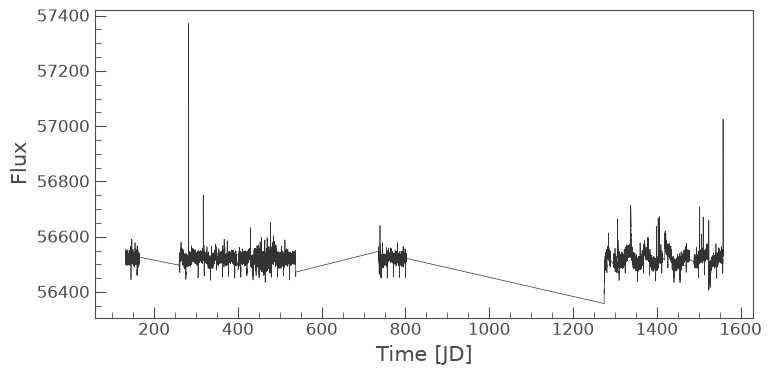

In [6]:
ax = md_lk.plot()
plt.show();

# Try 1: Approximating by Eye

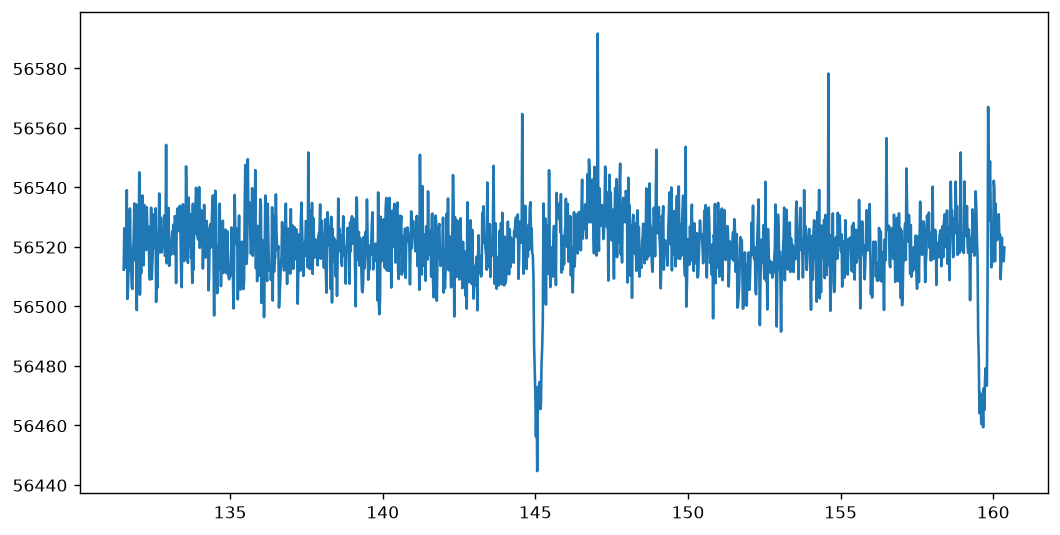

In [7]:
fig, ax = plt.subplots(figsize=(10,5),dpi=125)
ax.plot(myst_data['BKJD'][0:1400], myst_data['SAP_FLUX'][0:1400])
plt.show()

### There is a noticeable dip in flux around 145 and 160 BKJD, which could be a transit. Approximate period at 14.5 days.

In [8]:
transit_time = myst_data['BKJD'][np.argmin(myst_data['SAP_FLUX'][0:1400])]
transit_time

np.float64(145.06086049973965)

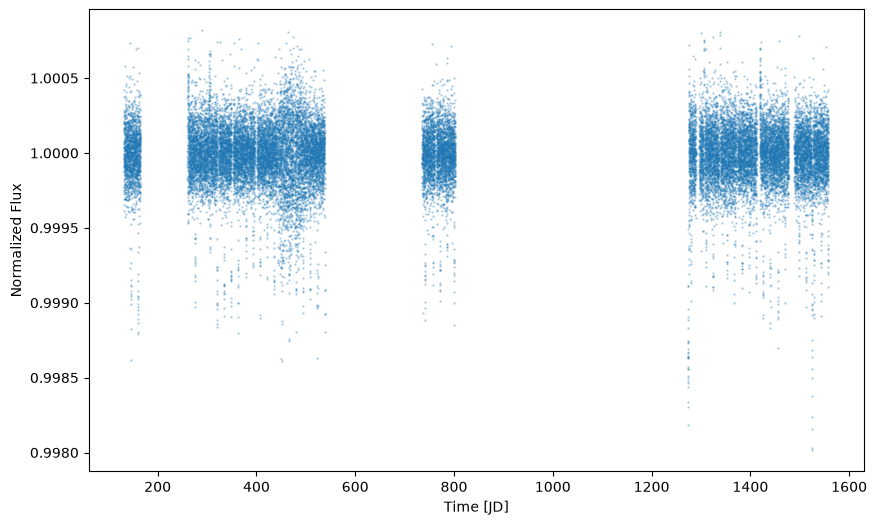

In [9]:
# Defining some important parameters

period = 14.5
transit_duration = 1.0

# Create parameters based on by-eye iteration

transit_mask = md_lk.create_transit_mask(
        period=period,
        transit_time=transit_time,
        duration=transit_duration)

flat_lc = md_lk.flatten(
        window_length=73,
        mask=transit_mask).remove_outliers(sigma_upper=4.0, sigma_lower=10.0)

fig, ax = plt.subplots(figsize=(10, 6))

flat_lc.scatter(ax=ax, s=2, alpha=0.3)

plt.show()

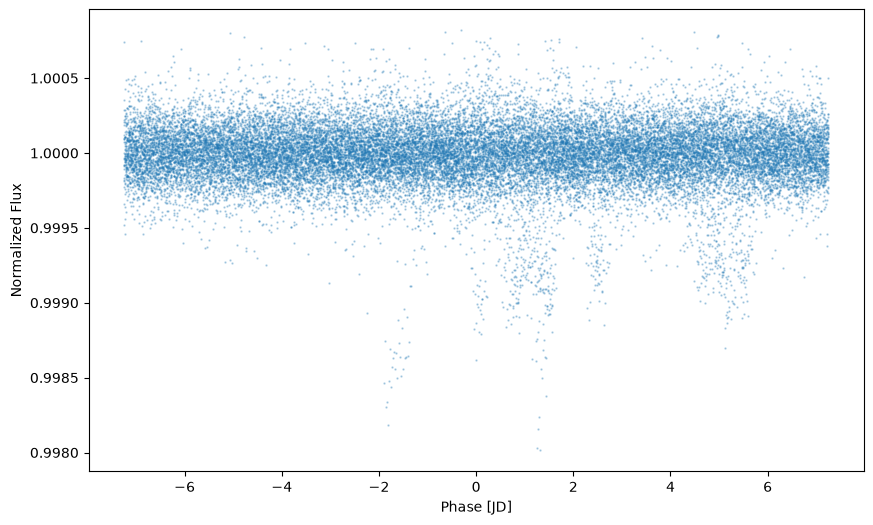

In [10]:
# Folding the new combined light curve

folded = flat_lc.fold(
    period=period,
    epoch_time=transit_time
)

# Plotting and formatting to troubleshoot

fig, ax = plt.subplots(figsize=(10, 6))

folded.scatter(ax=ax, s=2, alpha=0.3)

plt.show()

In [11]:
# Defining the number of bins, bin size, and other binning parameters

bin_size_days = 1 / (24 * 6)

binned = folded.bin(time_bin_size=bin_size_days).normalize()

Number of observations: 29381
Time range: 131.51281835371628 to 1557.9592205123045
Flux range: 0.9980137248854177 to 1.0008177553560154
Median flux: 0.9999972074967926
Flux standard deviation: 0.00021097338999674439

Folded observations: 29381
Folded time range: -7.249846387188882 to 7.249376925639808
Binned observations: 2088
Binned flux range: 0.9996748446000353 to 1.000224116081623


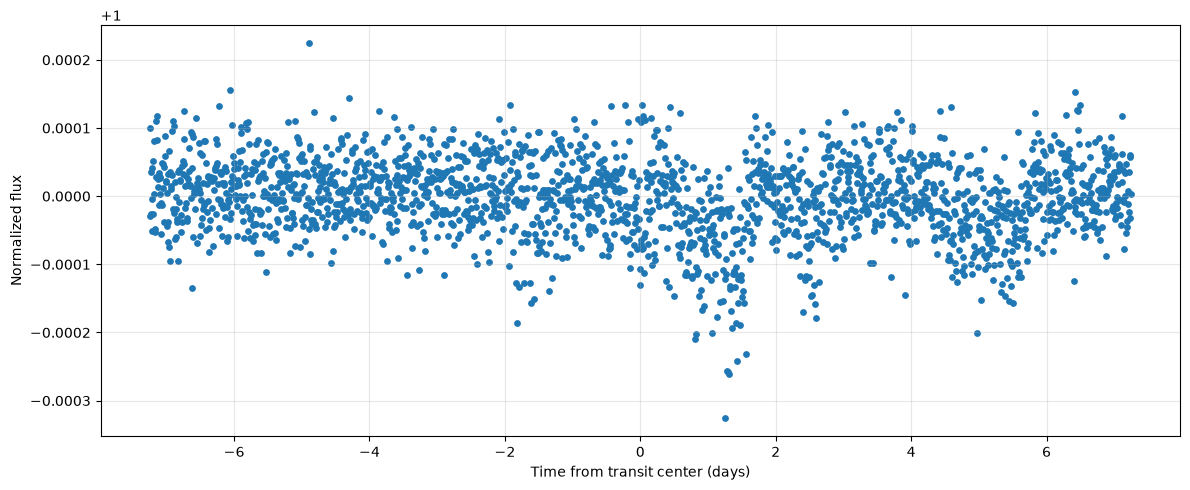

In [12]:
# Scatter plot using binned time and flux values, plus printing some data

print("Number of observations:", len(flat_lc.time))
print("Time range:", flat_lc.time.min(), "to", flat_lc.time.max())
print("Flux range:", np.nanmin(flat_lc.flux), "to", np.nanmax(flat_lc.flux))
print("Median flux:", np.nanmedian(flat_lc.flux))
print("Flux standard deviation:", np.nanstd(flat_lc.flux))

print("\nFolded observations:", len(folded.time))
print("Folded time range:", folded.time.min(), "to", folded.time.max())
print("Binned observations:", len(binned.time))
print("Binned flux range:", np.nanmin(binned.flux), "to", np.nanmax(binned.flux))

fig, ax = plt.subplots(figsize=(12, 5))

ax.scatter(
    binned.time.value,
    binned.flux.value,
    s=15
)

#ax.set_xlim(-0.2, 0.2)
#ax.set_ylim(0.998, 1.001)
ax.set_xlabel("Time from transit center (days)")
ax.set_ylabel("Normalized flux")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Try 2: Constrained or Unconstrained Periodogram: Lomb-Scargle

Most prominent frequency: 0.0716 1 / d
Corresponding period: 13.9716 d


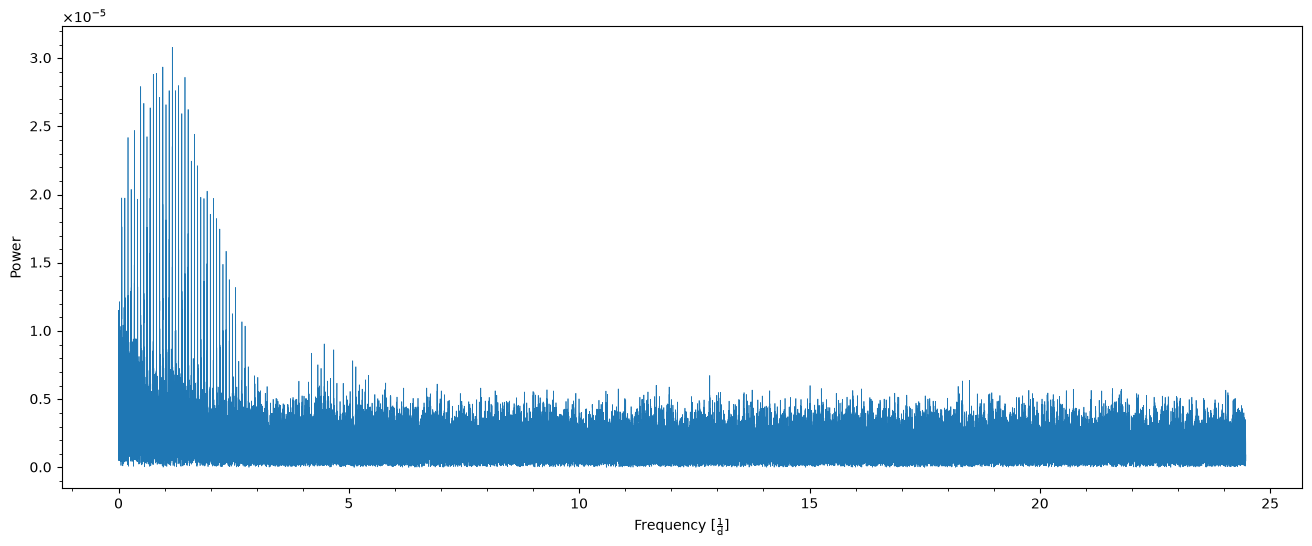

In [13]:
# Use by eye approximation to constrain: 14.5 +/- 1.5 days
pg = md_lk.to_periodogram(method="lombscargle",
                            minimum_frequency = 1/15,
                            maximum_frequency = 1/13,
                            oversample_factor=5)
best_frequency = pg.frequency_at_max_power
best_period = pg.period_at_max_power
print(f"Most prominent frequency: {best_frequency.value:.4f} {best_frequency.unit}")
print(f"Corresponding period: {best_period.value:.4f} {best_period.unit}")

fig, ax = plt.subplots(figsize=(16,6))
flat_lc.to_periodogram().plot(ax=ax)
plt.show()

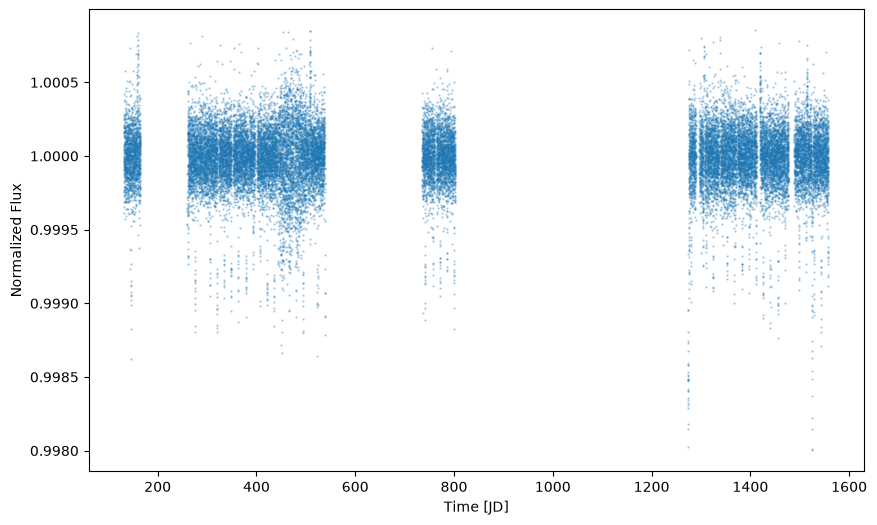

In [14]:
# Create parameters based on by-eye iteration

transit_mask2 = md_lk.create_transit_mask(
        period=best_period,
        transit_time=transit_time,
        duration=transit_duration)

flat_lc2 = md_lk.flatten(window_length=73,
                         mask=transit_mask2).remove_outliers(sigma_upper=4.0, sigma_lower=10.0)

fig, ax = plt.subplots(figsize=(10, 6))

flat_lc2.scatter(ax=ax, s=2, alpha=0.3)

plt.show()

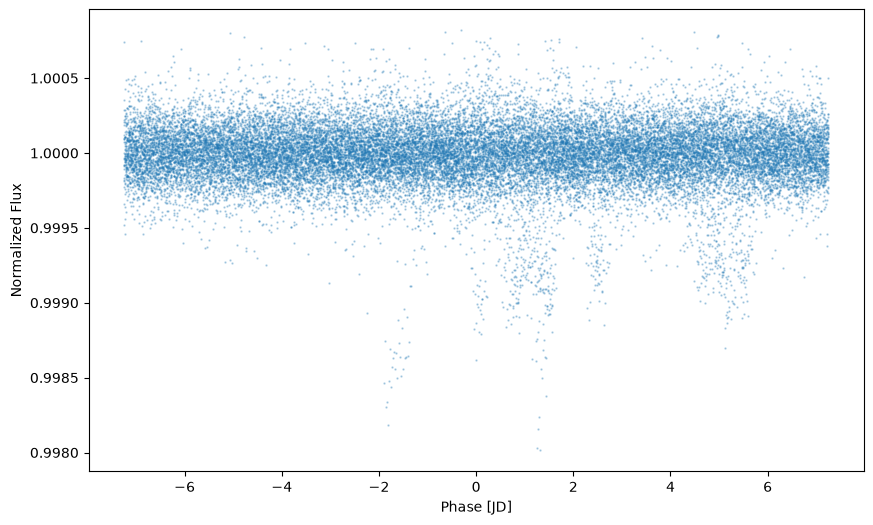

In [15]:
# Folding the new combined light curve

folded2 = flat_lc2.fold(
    period=best_period,
    epoch_time=transit_time
)

# Plotting and formatting to troubleshoot

fig, ax = plt.subplots(figsize=(10, 6))

folded.scatter(ax=ax, s=2, alpha=0.3)

plt.show()

In [16]:
# Defining the number of bins, bin size, and other binning parameters

bin_size_days2 = 1 / (24 * 6)

binned2 = folded2.bin(time_bin_size=bin_size_days2).normalize()


Folded observations: 29381
Folded time range: -7.249846387188882 to 7.249376925639808
Binned observations: 2012
Binned flux range: 0.9997852724878799 to 1.0001824430788715


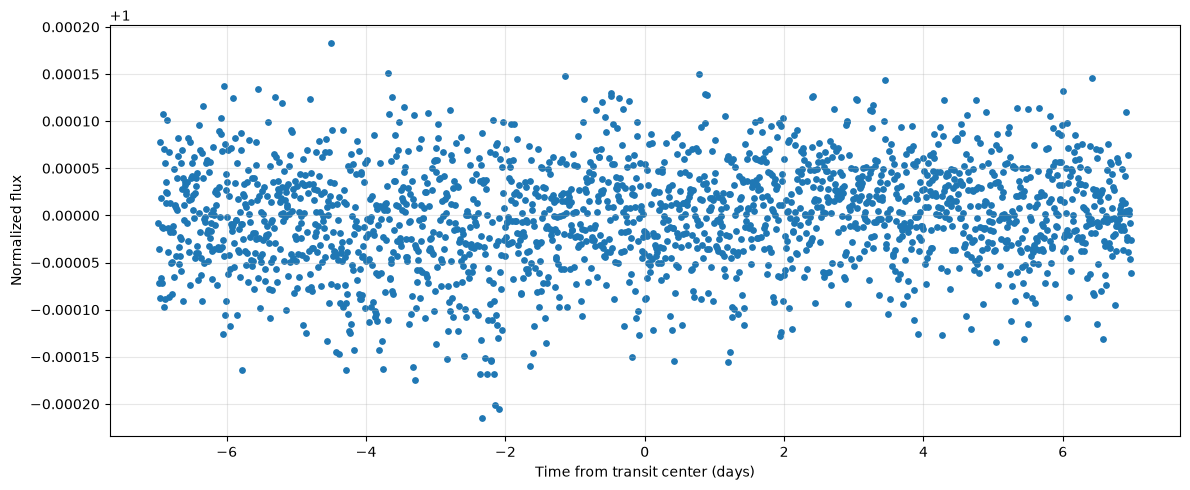

In [17]:
# Scatter plot using binned time and flux values, plus printing some data

print("\nFolded observations:", len(folded.time))
print("Folded time range:", folded.time.min(), "to", folded.time.max())
print("Binned observations:", len(binned2.time))
print("Binned flux range:", np.nanmin(binned2.flux), "to", np.nanmax(binned2.flux))

fig, ax = plt.subplots(figsize=(12, 5))

ax.scatter(
    binned2.time.value,
    binned2.flux.value,
    s=15
)

#ax.set_xlim(-0.2, 0.2)
#ax.set_ylim(0.998, 1.001)
ax.set_xlabel("Time from transit center (days)")
ax.set_ylabel("Normalized flux")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Try 3: Boxed Least Squares

In [18]:
flat_lc3 = md_lk.remove_outliers(sigma_upper=4.0, sigma_lower=10.0).flatten(window_length=73)

In [19]:
# Box least squares period search
periods = np.arange(12, 18, 0.001)
bls = flat_lc3.to_periodogram(method='bls', period=periods)
period3 = bls.period_at_max_power
t0 =  bls.transit_time_at_max_power
duration = bls.duration_at_max_power
print(f"{period3}\n{t0}\n{duration}")

`period` contains 113029 points.Periodogram is likely to be large, and slow to evaluate. Consider setting `frequency_factor` to a higher value.


14.556999999998585 d
145.11281835371628
0.33 d


In [20]:
mask = md_lk.create_transit_mask(period=period3, transit_time=t0, duration=duration * 2)
flat = md_lk.flatten(window_length=window, polyorder=2, mask=mask)
folded = flat.fold(period=period3, epoch_time=t0)

TypeError: cannot write to unmasked output